# Álgebra linear nas redes de Petri
## Da multiplicação de matrizes à evolução da marcação

**Informática Aplicada · aula teórica e prática em Python**

Vamos acompanhar uma rede com quatro lugares e seis transições. Primeiro,
relembraremos como se calcula o produto de matrizes. Depois, usaremos esse
produto para explicar o deslocamento das fichas e verificar cada disparo.

![PetriNetAlgebra](img/PN_algebraLinear.png)


O notebook contém explicações, cálculos manuais, código executável, um
visualizador de disparos e os links dos modelos
no GitHub. Os trechos da animação acompanham a explicação, e o GIF completo
está ao final. As imagens e os GIFs estão na pasta `img`.

### Como trabalhar com este material

Execute as células de código na ordem. As saídas já estão salvas para leitura.
Nos exemplos de exploração, altere os valores indicados e execute novamente.
No site, use **Show code** para abrir os códigos que estão recolhidos.

**Organização dos arquivos:** salve o arquivo **.ipynb** e crie uma pasta
chamada **img** ao lado dele. Coloque nessa pasta os nove arquivos PNG e GIF
fornecidos separadamente, mantendo exatamente os nomes:

- PN_algebraLinear.png
- rede_marcacao_inicial.png
- habilitacao_t5.png
- t1_primeiro_disparo.gif
- t4_dois_disparos.gif
- t5_t6_fechamento.gif
- caminho_t2.gif
- caminho_t3.gif
- rede_petri_corrigida.gif

Os caminhos usados nas células Markdown são relativos, como
**img/PN_algebraLinear.png**. No site, publique os arquivos na pasta **img**
correspondente ao notebook. Depois de salvá-los, reabra o notebook ou
atualize a página para carregar as imagens e as animações.

**Preparação para uso offline:** instale Python, Jupyter, NumPy, Matplotlib
e Pillow enquanto houver conexão. Depois, o conteúdo principal deste notebook
funciona sem internet. Os modelos PIPE2 e HPSim podem ser baixados pelos links
da seção 6.

No terminal, se ainda precisar preparar o ambiente:

    python -m pip install notebook numpy matplotlib pillow
    jupyter notebook

Os simuladores PIPE2 e HPSim precisam estar instalados para abrir seus
respectivos arquivos; não são necessários para executar os cálculos em Python.


### Objetivos e roteiro

Ao final, você deverá conseguir:

1. identificar as dimensões de matrizes e vetores;
2. calcular um produto pelo procedimento **linha × coluna**;
3. interpretar cada coluna da matriz de incidência como uma variação de fichas;
4. calcular a nova marcação e verificar se o disparo é permitido;
5. distinguir o vetor de um disparo da contagem acumulada de disparos.


### Preparação dos cálculos e das exibições

O código seguinte importa as bibliotecas usadas nos cálculos e nas imagens,
configura a apresentação dos números e define funções para exibir matrizes,
tabelas e figuras. Ele prepara o ambiente para as próximas células;
os exemplos da aula começam logo depois.


In [13]:
import base64
import html
import io
from pathlib import Path
from PIL import Image as PILImage

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, FancyArrowPatch
from IPython.display import display, HTML, Math, Image

np.set_printoptions(suppress=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})


def latex_matriz(A):
    """Converte uma matriz pequena em LaTeX para exibição no notebook."""
    A = np.asarray(A)
    if A.ndim == 1:
        A = A.reshape(-1, 1)
    linhas = [" & ".join(str(int(x)) for x in linha) for linha in A]
    return r"\begin{bmatrix}" + r" \\ ".join(linhas) + r"\end{bmatrix}"


def mostrar_matriz(nome, A):
    display(Math(nome + " = " + latex_matriz(A)))


def tabela(titulo, cabecalho, linhas):
    """Tabela sem dependência de pandas e sem recursos externos."""
    th = "".join(f"<th>{html.escape(str(c))}</th>" for c in cabecalho)
    corpo = "".join(
        "<tr>" + "".join(f"<td>{html.escape(str(v))}</td>" for v in linha) + "</tr>"
        for linha in linhas
    )
    estilo = """<style>
    .aula-tabela{border-collapse:collapse;margin:12px 0;font-size:14px}
    .aula-tabela th,.aula-tabela td{border:1px solid #d5dee9;padding:7px 11px;text-align:center}
    .aula-tabela th{background:#eaf3fd;color:#163f6b}
    .aula-tabela tr:nth-child(even){background:#f6f8fb}
    </style>"""
    display(HTML(estilo + f"<b>{html.escape(titulo)}</b>"
                 + f'<table class="aula-tabela"><thead><tr>{th}</tr></thead><tbody>{corpo}</tbody></table>'))


def mostrar_figura(figura):
    """Salva a imagem na própria saída, para que também possa ser lida offline."""
    buffer = io.BytesIO()
    figura.savefig(buffer, format="png", dpi=125, bbox_inches="tight", facecolor="white")
    display(Image(data=buffer.getvalue()))
    plt.close(figura)


print("Ambiente pronto. NumPy:", np.__version__)

Ambiente pronto. NumPy: 2.1.3


## 1. Revisão: matrizes, vetores e dimensões

Uma matriz organiza números em **linhas** e **colunas**. Se possui $m$ linhas
e $n$ colunas, sua dimensão é $m\times n$. O elemento $a_{ij}$ ocupa a linha
$i$ e a coluna $j$.

Um **vetor coluna** tem uma única coluna. Um vetor de quatro componentes,
escrito como coluna, tem dimensão $4\times1$. Sua transposta é um vetor linha
de dimensão $1\times4$:

$$
x=\begin{bmatrix}1\\0\\2\\0\end{bmatrix},
\qquad x^T=\begin{bmatrix}1&0&2&0\end{bmatrix}.
$$

A ordem dos componentes faz parte da informação. Na rede, usaremos sempre
os lugares na ordem **P1, P2, P3, P4** e as transições na ordem
**T1, T2, T3, T4, T5, T6**.

No NumPy, `[[1], [0], [2], [0]]` representa uma matriz $4\times1$.
Já `[1, 0, 2, 0]` cria um array de uma dimensão, com `shape == (4,)`.
Nesta aula, manteremos os vetores como colunas para que as dimensões fiquem explícitas.

In [2]:
x = np.array([[1], [0], [2], [0]], dtype=int)
mostrar_matriz("x", x)
mostrar_matriz("x^T", x.T)
print("Dimensão de x:", x.shape)
print("Dimensão de x.T:", x.T.shape)
print("Dimensão de um array unidimensional:", np.array([1, 0, 2, 0]).shape)

Dimensão de x: (4, 1)
Dimensão de x.T: (1, 4)
Dimensão de um array unidimensional: (4,)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 1.1 Quando é possível multiplicar?

Para calcular $D=AB$, o número de **colunas de $A$** deve ser igual ao número
de **linhas de $B$**:

$$
\underbrace{A}_{m\times n}\;
\underbrace{B}_{n\times p}
=\underbrace{D}_{m\times p}.
$$

As dimensões internas precisam coincidir. As dimensões externas indicam o
tamanho do resultado. Cada elemento de $D$ é obtido multiplicando uma linha
de $A$ por uma coluna de $B$ e somando os produtos:

$$d_{ij}=\sum_{k=1}^{n}a_{ik}b_{kj}.$$

**Não multiplicamos apenas posições correspondentes.** Cada elemento do
resultado depende de uma linha inteira e de uma coluna inteira.

### 1.2 Exemplo manual: linha × coluna

Considere:

$$
A=\begin{bmatrix}1&2&0\\-1&3&1\end{bmatrix}_{2\times3},
\qquad
B=\begin{bmatrix}2&1\\0&4\\5&-2\end{bmatrix}_{3\times2}.
$$

O resultado terá dimensão $2\times2$. Vamos calcular suas quatro posições:

$$
\begin{aligned}
d_{11}&=1\cdot2+2\cdot0+0\cdot5=2,\\
d_{12}&=1\cdot1+2\cdot4+0\cdot(-2)=9,\\
d_{21}&=(-1)\cdot2+3\cdot0+1\cdot5=3,\\
d_{22}&=(-1)\cdot1+3\cdot4+1\cdot(-2)=9.
\end{aligned}
$$

Portanto, $AB=\begin{bmatrix}2&9\\3&9\end{bmatrix}$.
Na expressão $d_{21}$, usamos a **segunda linha** de $A$ e a **primeira coluna** de $B$.

In [14]:
A = np.array([[1, 2, 0], [-1, 3, 1]], dtype=int)
B = np.array([[2, 1], [0, 4], [5, -2]], dtype=int)


def produto_linha_coluna(A, B):
    """Versão didática do produto matricial, com os três índices explícitos."""
    A, B = np.asarray(A), np.asarray(B)
    if A.ndim != 2 or B.ndim != 2 or A.shape[1] != B.shape[0]:
        raise ValueError("As dimensões internas precisam coincidir.")
    D = np.zeros((A.shape[0], B.shape[1]), dtype=np.result_type(A, B))
    for i in range(A.shape[0]):
        for j in range(B.shape[1]):
            for k in range(A.shape[1]):
                D[i, j] += A[i, k] * B[k, j]
    return D


D_manual = produto_linha_coluna(A, B)
D_numpy = A @ B
mostrar_matriz("AB", D_numpy)
print("Dimensões:", A.shape, "@", B.shape, "=", D_numpy.shape)
assert np.array_equal(D_manual, [[2, 9], [3, 9]])
assert np.array_equal(D_manual, D_numpy)

<IPython.core.display.Math object>

Dimensões: (2, 3) @ (3, 2) = (2, 2)


### 1.3 `@` e `*` fazem operações diferentes no NumPy

Para arrays do NumPy, use **`A @ B`** no produto matricial. O operador
**`A * B`** faz o produto elemento a elemento quando as dimensões são compatíveis
com as regras do NumPy. Esses resultados geralmente são diferentes.

Além disso, o produto matricial **não é comutativo em geral**: $AB$ e $BA$
podem ser diferentes, ou um dos produtos pode nem estar definido. A ordem
dos fatores não pode ser trocada livremente.

In [15]:
U = np.array([[1, 2], [3, 4]], dtype=int)
V = np.array([[5, 6], [7, 8]], dtype=int)
mostrar_matriz("UV", U @ V)
mostrar_matriz(r"U \;{*}\; V", U * V)
mostrar_matriz("VU", V @ U)
print("U @ V é igual a V @ U?", np.array_equal(U @ V, V @ U))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

U @ V é igual a V @ U? False



### 1.4 Produto por um vetor: combinação de colunas

Se $A=[a_1\ a_2\ a_3]$, em que cada $a_j$ é uma coluna, então:

$$Ax=x_1a_1+x_2a_2+x_3a_3.$$

O produto é uma **combinação linear das colunas**. Em particular, o vetor
$e_2=[0\ 1\ 0]^T$ seleciona a segunda coluna:

$$Ae_2=0a_1+1a_2+0a_3=a_2.$$

Essa propriedade explica o papel do vetor de disparo na rede de Petri.

Retomando a matriz do exemplo da seção 1.2:

$$
A=\begin{bmatrix}1&2&0\\-1&3&1\end{bmatrix},
\qquad
e_2=\begin{bmatrix}0\\1\\0\end{bmatrix}.
$$

As colunas de $A$ são $a_1=[1\ {-1}]^T$, $a_2=[2\ 3]^T$ e
$a_3=[0\ 1]^T$. Como somente a segunda componente de $e_2$ vale 1:

$$
Ae_2=0\begin{bmatrix}1\\-1\end{bmatrix}
     +1\begin{bmatrix}2\\3\end{bmatrix}
     +0\begin{bmatrix}0\\1\end{bmatrix}
     =\begin{bmatrix}2\\3\end{bmatrix}.
$$

Portanto, o resultado é a **segunda coluna da mesma matriz $A$**.


In [16]:
e2 = np.array([[0], [1], [0]], dtype=int)
mostrar_matriz("Ae_2", A @ e2)
print("Segunda coluna de A, preservada como coluna:")
print(A[:, 1:2])
assert np.array_equal(A @ e2, A[:, 1:2])

# Em Python, os índices começam em zero: a coluna matemática 2 tem índice 1.

<IPython.core.display.Math object>

Segunda coluna de A, preservada como coluna:
[[2]
 [3]]


## 2. A rede utilizada na aula

Um **lugar** representa uma condição ou um recurso; uma **transição** representa
um evento; as **fichas** indicam a situação atual. O conjunto de quantidades
de fichas nos lugares é a **marcação**.

![Rede na marcação inicial: uma ficha em P1 e T1, T2 e T3 habilitadas.](img\rede_marcacao_inicial.png)

**Leitura da figura:** os círculos são lugares, as barras são transições
e o ponto em P1 é uma ficha. As setas indicam o sentido de consumo e produção.
Os arcos sem número têm peso 1; os números 2 indicam produção de duas fichas.
As duas setas de P3 para T5 representam consumo total de duas fichas.

Quem dispara é a **transição**. Um lugar contém ou fornece fichas; ele não dispara.
O peso de um arco indica quantas fichas são consumidas ou produzidas por disparo.

| Transição | Consome | Produz |
|---|---|---|
| T1 | 1 ficha de P1 | **2 fichas em P2** |
| T2 | 1 ficha de P1 | 1 ficha em P2 e 1 em P3 |
| T3 | 1 ficha de P1 | **2 fichas em P3** |
| T4 | 1 ficha de P2 | 1 ficha em P3 |
| T5 | **2 fichas de P3** | 1 ficha em P4 |
| T6 | 1 ficha de P4 | 1 ficha em P1 |

A marcação inicial é $M_0=[1\ 0\ 0\ 0]^T$. Os dois arcos paralelos de P3 para T5
têm consumo total 2, equivalente a um único arco de peso 2.

Após T1, **T4 precisa disparar duas vezes** para transferir as duas fichas
de P2 para P3. Após T3, T5 já pode disparar, porque recebe as duas fichas de uma vez.

### 2.1 Matrizes de entrada, saída e incidência

Usaremos a convenção **linhas = lugares** e **colunas = transições**.

- $Pre_{ij}$: quantidade consumida de $P_i$ pelo disparo de $T_j$;
- $Post_{ij}$: quantidade produzida em $P_i$ pelo disparo de $T_j$;
- $C=Post-Pre$: variação líquida da marcação.

As três matrizes têm dimensão $4\times6$. Em $C$, um valor negativo indica
consumo líquido; um positivo indica produção líquida. O zero representa
variação líquida nula. Em uma rede com laços, zero também pode resultar de
consumo e produção iguais: por isso, $Pre$ e $Post$ devem ser preservadas.

Na figura, observe a rede à esquerda e a matriz de incidência à direita.
Por exemplo, T1 consome uma ficha de P1 e produz duas em P2:
$Pre_{P1,T1}=1$, $Post_{P2,T1}=2$, e a coluna de T1 em $C$
é $[-1\ 2\ 0\ 0]^T$. Para T5, o consumo de duas fichas em P3
aparece como $-2$ na linha P3 e na coluna T5 de $C$.

![A rede original e sua matriz de incidência, com lugares nas linhas e transições nas colunas.](img/PN_algebraLinear.png)


In [17]:
LUGARES = ["P1", "P2", "P3", "P4"]
TRANSICOES = ["T1", "T2", "T3", "T4", "T5", "T6"]

Pre = np.array([
    [1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 0],
    [0, 0, 0, 0, 2, 0],
    [0, 0, 0, 0, 0, 1],
], dtype=int)

Post = np.array([
    [0, 0, 0, 0, 0, 1],
    [2, 1, 0, 0, 0, 0],
    [0, 1, 2, 1, 0, 0],
    [0, 0, 0, 0, 1, 0],
], dtype=int)

C = Post - Pre
M0 = np.array([[1], [0], [0], [0]], dtype=int)

mostrar_matriz("Pre", Pre)
mostrar_matriz("Post", Post)
mostrar_matriz("C=Post-Pre", C)
tabela("Leitura da matriz C", ["Lugar / transição"] + TRANSICOES,
       [[p] + C[i].tolist() for i, p in enumerate(LUGARES)])
assert C.shape == (4, 6) and M0.shape == (4, 1)
assert C[1, 0] == 2 and C[2, 2] == 2 and C[2, 4] == -2

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Lugar / transição,T1,T2,T3,T4,T5,T6
P1,-1,-1,-1,0,0,1
P2,2,1,0,-1,0,0
P3,0,1,2,1,-2,0
P4,0,0,0,0,1,-1


### 2.2 Regra de habilitação

![T5 não habilitada com uma ficha em P3 e habilitada com duas fichas em P3.](img\habilitacao_t5.png)

Os dois quadros foram retirados da mesma animação. À esquerda, em $M_2$,
P3 tem uma ficha; à direita, em $M_3$, tem duas. A barra de T5 passa
de cinza para azul quando seu requisito de entrada é atendido.

Antes de atualizar a marcação, verificamos se há fichas suficientes em **cada**
lugar de entrada. Para a transição $T_j$:

$$M\geq Pre_{:,j},$$

com comparação componente a componente. Assim, T5 exige $M(P3)\geq2$.
Ter apenas uma ficha em P3 não habilita T5.

O modelo didático abaixo é uma rede lugar/transição com arcos ordinários
ponderados. Não usamos temporização, prioridades, arcos inibidores nem
disparo simultâneo.

In [19]:
def coluna_marcacao(M):
    A = np.asarray(M)
    if A.shape not in ((4,), (4, 1)):
        raise ValueError("Use quatro valores, na ordem P1, P2, P3, P4.")
    if not np.all(np.isfinite(A)) or not np.all(A == np.floor(A)) or np.any(A < 0):
        raise ValueError("As quantidades de fichas devem ser inteiros não negativos.")
    return A.astype(int).reshape(4, 1)


def vetor_disparo(transicao):
    if transicao not in TRANSICOES:
        raise ValueError("Transição desconhecida: " + str(transicao))
    sigma = np.zeros((6, 1), dtype=int)
    sigma[TRANSICOES.index(transicao), 0] = 1
    return sigma


def habilitadas(M):
    M = coluna_marcacao(M)
    return [t for j, t in enumerate(TRANSICOES) if np.all(M >= Pre[:, j:j+1])]


def disparar(M, transicao):
    """Verifica a habilitação e devolve uma nova marcação; não altera M."""
    M = coluna_marcacao(M)
    sigma = vetor_disparo(transicao)
    if transicao not in habilitadas(M):
        raise ValueError(f"{transicao} não está habilitada em {M.ravel().tolist()}.")
    return M + C @ sigma


print("Transições habilitadas em M0:", habilitadas(M0))

Transições habilitadas em M0: ['T1', 'T2', 'T3']


In [20]:
# Reutiliza os quadros do GIF original, sem redesenhar a rede.
ARQUIVO_GIF = Path("img/rede_petri_corrigida.gif")
INICIO_CAMINHO = {"T1": 0, "T2": 11, "T3": 20}


def mostrar_quadro_gif(indice):
    """Mostra um quadro fixo, incluindo a rede e os cálculos sincronizados."""
    with PILImage.open(ARQUIVO_GIF) as animacao:
        animacao.seek(indice)
        quadro = animacao.convert("RGB")
    buffer = io.BytesIO()
    quadro.save(buffer, format="PNG")
    display(Image(data=buffer.getvalue(), width=1100))


## 3. A equação de atualização da marcação

Para um disparo por vez, definimos o vetor coluna $\sigma_{k+1}$ com seis
componentes: uma componente igual a 1 na posição da transição escolhida e
as demais iguais a zero. Então:

$$\boxed{M_{k+1}=M_k+C\sigma_{k+1}}.$$

| Símbolo | Interpretação | Dimensão |
|---|---|---|
| $M_k$ | marcação antes do disparo | $4\times1$ |
| $C$ | matriz de incidência | $4\times6$ |
| $\sigma_{k+1}$ | vetor do disparo deste passo | $6\times1$ |
| $C\sigma_{k+1}$ | variação $\Delta M$ | $4\times1$ |
| $M_{k+1}$ | marcação depois do disparo | $4\times1$ |

O produto é possível porque as dimensões internas são iguais a 6.
A soma é possível porque $M_k$ e $C\sigma_{k+1}$ têm a mesma dimensão.
O índice $k$ indica o **passo da execução**, não o número da transição.

### 3.1 Primeiro disparo: T1, calculado à mão

Na ordem T1 a T6, o vetor do primeiro disparo é
$\sigma_1=[1\ 0\ 0\ 0\ 0\ 0]^T$. Multiplicamos cada linha de $C$ por essa coluna:

$$
C\sigma_1=
\begin{bmatrix}
(-1)1+(-1)0+(-1)0+0(0)+0(0)+1(0)\\
2(1)+1(0)+0(0)+(-1)0+0(0)+0(0)\\
0(1)+1(0)+2(0)+1(0)+(-2)0+0(0)\\
0(1)+0(0)+0(0)+0(0)+1(0)+(-1)0
\end{bmatrix}
=\begin{bmatrix}-1\\2\\0\\0\end{bmatrix}.
$$

A **base canônica** de $\mathbb{R}^6$ é o conjunto dos seis vetores
$e_1,\ldots,e_6$: cada um tem 1 em uma posição e 0 nas outras.
Assim, $e_1=[1\ 0\ 0\ 0\ 0\ 0]^T$ e
$e_4=[0\ 0\ 0\ 1\ 0\ 0]^T$. Neste primeiro passo,
$\sigma_1=e_1$: a componente de T1 vale 1. Ao multiplicar, a primeira
coluna de $C$ é multiplicada por 1 e todas as outras por 0. Por isso,
o produto seleciona a **primeira coluna de $C$**. Em seguida:

$$
M_1=
\begin{bmatrix}1\\0\\0\\0\end{bmatrix}
+\begin{bmatrix}-1\\2\\0\\0\end{bmatrix}
=\begin{bmatrix}0\\2\\0\\0\end{bmatrix}.
$$

Compare, em cada linha, a marcação **antes** ($M_0$) com a marcação
**depois** ($M_1$). A variação é $\Delta M=M_1-M_0$:

| Lugar | Antes: $M_0$ | Variação: $C\sigma_1$ | Depois: $M_1$ |
|---|---:|---:|---:|
| P1 | 1 | $-1$ | 0 |
| P2 | 0 | $+2$ | 2 |
| P3 | 0 | 0 | 0 |
| P4 | 0 | 0 | 0 |

P1 passa de 1 para 0: uma ficha é consumida. P2 passa de 0 para 2:
duas fichas são produzidas. P3 e P4 mantêm suas quantidades.

Os números negativos pertencem à **variação**; a quantidade de fichas na
marcação continua sendo um inteiro não negativo.

O trecho mostra a marcação inicial, a preparação do disparo e o resultado de T1:

![Trecho do GIF original: antes e depois do primeiro disparo de T1.](img/t1_primeiro_disparo.gif)


In [22]:
sigma1 = vetor_disparo("T1")
delta1 = C @ sigma1
M1 = disparar(M0, "T1")

mostrar_matriz(r"\sigma_1", sigma1)
mostrar_matriz(r"C\sigma_1", delta1)
mostrar_matriz("M_1", M1)

contas = []
for i, lugar in enumerate(LUGARES):
    termos = [f"({C[i, j]})×{sigma1[j, 0]}" for j in range(6)]
    contas.append([lugar, " + ".join(termos), int(delta1[i, 0]), int(M1[i, 0])])
tabela("Cada linha de C multiplicada pelo vetor do disparo", ["Lugar", "Produtos e soma", "ΔM", "M depois"], contas)
assert np.array_equal(delta1, [[-1], [2], [0], [0]])
assert np.array_equal(M1, [[0], [2], [0], [0]])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Lugar,Produtos e soma,ΔM,M depois
P1,(-1)×1 + (-1)×0 + (-1)×0 + (0)×0 + (0)×0 + (1)×0,-1,0
P2,(2)×1 + (1)×0 + (0)×0 + (-1)×0 + (0)×0 + (0)×0,2,2
P3,(0)×1 + (1)×0 + (2)×0 + (1)×0 + (-2)×0 + (0)×0,0,0
P4,(0)×1 + (0)×0 + (0)×0 + (0)×0 + (1)×0 + (-1)×0,0,0


### 3.2 Dois disparos de T4

Depois de T1, temos duas fichas em P2. Cada disparo de T4 consome **uma**
ficha de P2 e produz **uma** em P3:

$$C e_4=\begin{bmatrix}0\\-1\\1\\0\end{bmatrix}.$$

Assim:

$$
\begin{aligned}
M_2&=\begin{bmatrix}0\\2\\0\\0\end{bmatrix}
    +\begin{bmatrix}0\\-1\\1\\0\end{bmatrix}
    =\begin{bmatrix}0\\1\\1\\0\end{bmatrix},\\
M_3&=\begin{bmatrix}0\\1\\1\\0\end{bmatrix}
    +\begin{bmatrix}0\\-1\\1\\0\end{bmatrix}
    =\begin{bmatrix}0\\0\\2\\0\end{bmatrix}.
\end{aligned}
$$

Em $M_2$, T5 ainda não está habilitada. Somente em $M_3$ P3 reúne as duas fichas.
Neste trecho, acompanhe os dois disparos de T4 e compare as marcações
$M_1$, $M_2$ e $M_3$ com as contas acima. Cada disparo transfere apenas uma ficha.

![Trecho do GIF original: os dois disparos sucessivos de T4.](img/t4_dois_disparos.gif)


In [23]:
M2 = disparar(M1, "T4")
M3 = disparar(M2, "T4")
mostrar_matriz("M_2", M2)
print("Habilitadas em M2:", habilitadas(M2))

try:
    disparar(M2, "T5")
except ValueError as erro:
    print("Tentativa recusada corretamente:", erro)

mostrar_matriz("M_3", M3)
print("Habilitadas em M3:", habilitadas(M3))

<IPython.core.display.Math object>

Habilitadas em M2: ['T4']
Tentativa recusada corretamente: T5 não está habilitada em [0, 1, 1, 0].


<IPython.core.display.Math object>

Habilitadas em M3: ['T5']


### 3.3 T5 e T6 completam o ciclo

O vetor do disparo de T5 seleciona a quinta coluna de $C$:

$$C e_5=\begin{bmatrix}0\\0\\-2\\1\end{bmatrix}.$$

As duas fichas de P3 são consumidas no **mesmo disparo** de T5. Depois, T6
retira a ficha de P4 e produz uma em P1:

$$
M_4=\begin{bmatrix}0\\0\\0\\1\end{bmatrix},
\qquad
C e_6=\begin{bmatrix}1\\0\\0\\-1\end{bmatrix},
\qquad
M_5=\begin{bmatrix}1\\0\\0\\0\end{bmatrix}=M_0.
$$

Voltamos à marcação inicial. O ciclo iniciado por T1 foi:
**T1 → T4 → T4 → T5 → T6**.
O trecho começa em $M_3$, mostra T5 consumindo as duas fichas de P3
e termina com T6 devolvendo uma ficha a P1.

![Trecho do GIF original: T5 e T6 completam o ciclo iniciado por T1.](img/t5_t6_fechamento.gif)


In [24]:
M4 = disparar(M3, "T5")
M5 = disparar(M4, "T6")
mostrar_matriz("M_4", M4)
mostrar_matriz("M_5", M5)
assert np.array_equal(M5, M0)
print("Ciclo concluído: M5 é igual a M0.")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Ciclo concluído: M5 é igual a M0.


### 3.4 Um cuidado com as dimensões no Python

Na equação $M_1=M_0+C\sigma_1$, precisamos de uma **variação de quatro
componentes**, uma para cada lugar. Por isso, o produto deve resultar
em um vetor coluna $4\times1$.

| Expressão | Operação realizada | Dimensão do resultado |
|---|---|---|
| `C @ sigma1` | produto matricial: multiplica cada linha pela coluna e soma os seis produtos | $4\times1$ |
| `C * sigma1.ravel()` | produto elemento a elemento: multiplica cada coluna de `C` pelo respectivo componente de `sigma1` | $4\times6$ |

`ravel()` transforma o vetor $6\times1$ em um array de seis valores.
O NumPy repete esses valores em cada linha de `C` para realizar o produto
elemento a elemento. Como `sigma1` tem 1 somente na primeira posição,
essa operação mantém a primeira coluna de `C` e zera as outras cinco.
Ela **ainda não soma os produtos de cada linha**.

Somente depois de somar as seis colunas, com
`produto_elementar.sum(axis=1, keepdims=True)`, obtemos o mesmo vetor
$[-1\ 2\ 0\ 0]^T$ calculado por `C @ sigma1`. O argumento
`keepdims=True` mantém o resultado como uma coluna.

Na equação de atualização, use diretamente **`C @ sigma1`** e confira
se o resultado tem dimensão $(4,1)$ antes de somá-lo a `M0`.


In [12]:
produto_correto = C @ sigma1
produto_elementar = C * sigma1.ravel()
print("C @ sigma1:", produto_correto.shape)
print("C * sigma1.ravel():", produto_elementar.shape)
mostrar_matriz(r"C\sigma_1", produto_correto)
mostrar_matriz(r"\text{Produto elemento a elemento}", produto_elementar)
print("A soma das colunas do produto elementar recupera a combinação linear:")
print(produto_elementar.sum(axis=1, keepdims=True))
assert np.array_equal(produto_elementar.sum(axis=1, keepdims=True), produto_correto)

C @ sigma1: (4, 1)
C * sigma1.ravel(): (4, 6)
A soma das colunas do produto elementar recupera a combinação linear:
[[-1]
 [ 2]
 [ 0]
 [ 0]]


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 4. Os três caminhos completos

A ficha inicial de P1 habilita T1, T2 e T3. Isso cria uma **escolha**: nesta
aula, dispara apenas uma transição por vez. Depois da escolha, verificamos
as novas habilitações a cada passo.

| Caminho | Sequência de disparos |
|---|---|
| Começa por T1 | T1 → T4 → T4 → T5 → T6 |
| Começa por T2 | T2 → T4 → T5 → T6 |
| Começa por T3 | T3 → T5 → T6 |

Nos três casos, a execução completa retorna a $M_0$. A quantidade de passos
é diferente. Cada caminho abaixo começa novamente na mesma marcação inicial;
os índices $M_1,M_2,\ldots$ são locais ao caminho que está sendo examinado.

O caminho por T1 já foi acompanhado em três trechos na seção 3.
Para compará-lo com os outros, observe agora as alternativas iniciadas por T2 e T3.
Cada animação abaixo reinicia em $M_0$.

**Caminho por T2: T2 → T4 → T5 → T6.** T2 coloca uma ficha em P2 e uma em P3;
T4 transfere a ficha de P2 e completa as duas fichas exigidas por T5.

![Trecho do GIF original: caminho completo iniciado por T2.](img/caminho_t2.gif)

**Caminho por T3: T3 → T5 → T6.** T3 produz diretamente as duas fichas em P3;
por isso, este caminho dispensa o disparo de T4.

![Trecho do GIF original: caminho completo iniciado por T3.](img/caminho_t3.gif)

As tabelas seguintes conferem as marcações calculadas nos três caminhos.


In [26]:
CAMINHOS = {
    "T1": ["T1", "T4", "T4", "T5", "T6"],
    "T2": ["T2", "T4", "T5", "T6"],
    "T3": ["T3", "T5", "T6"],
}


def simular(sequencia, M_inicial=None):
    M = M0.copy() if M_inicial is None else coluna_marcacao(M_inicial)
    estados = [M.copy()]
    for transicao in sequencia:
        M = disparar(M, transicao)
        estados.append(M.copy())
    return estados


for nome, sequencia in CAMINHOS.items():
    estados = simular(sequencia)
    linhas = []
    for k, M in enumerate(estados):
        linhas.append([f"M{k}", "inicial" if k == 0 else sequencia[k-1]]
                      + M.ravel().tolist() + [", ".join(habilitadas(M))])
    tabela(f"Caminho iniciado por {nome}", ["Marcação", "Último disparo"] + LUGARES + ["Habilitadas"], linhas)
    assert np.array_equal(estados[-1], M0)

Marcação,Último disparo,P1,P2,P3,P4,Habilitadas
M0,inicial,1,0,0,0,"T1, T2, T3"
M1,T1,0,2,0,0,T4
M2,T4,0,1,1,0,T4
M3,T4,0,0,2,0,T5
M4,T5,0,0,0,1,T6
M5,T6,1,0,0,0,"T1, T2, T3"


Marcação,Último disparo,P1,P2,P3,P4,Habilitadas
M0,inicial,1,0,0,0,"T1, T2, T3"
M1,T2,0,1,1,0,T4
M2,T4,0,0,2,0,T5
M3,T5,0,0,0,1,T6
M4,T6,1,0,0,0,"T1, T2, T3"


Marcação,Último disparo,P1,P2,P3,P4,Habilitadas
M0,inicial,1,0,0,0,"T1, T2, T3"
M1,T3,0,0,2,0,T5
M2,T5,0,0,0,1,T6
M3,T6,1,0,0,0,"T1, T2, T3"


### 4.1 Avance um disparo por vez

Na próxima célula, escolha `CAMINHO = "T1"`, `"T2"` ou `"T3"` e indique
o número do `PASSO`. Execute a célula para ver a marcação **antes**, o vetor
de disparo, a variação e a marcação **depois**.

Não há avanço automático. Aumente `PASSO` quando terminar a explicação.
Os limites são 1 a 5 no caminho por T1, 1 a 4 no caminho por T2 e 1 a 3 no
caminho por T3. O visualizador mostra um quadro fixo do **mesmo GIF** usado nos trechos
acima. A cor laranja identifica a transição do passo selecionado;
os vetores à direita permitem comparar antes, variação e depois.

<IPython.core.display.Math object>

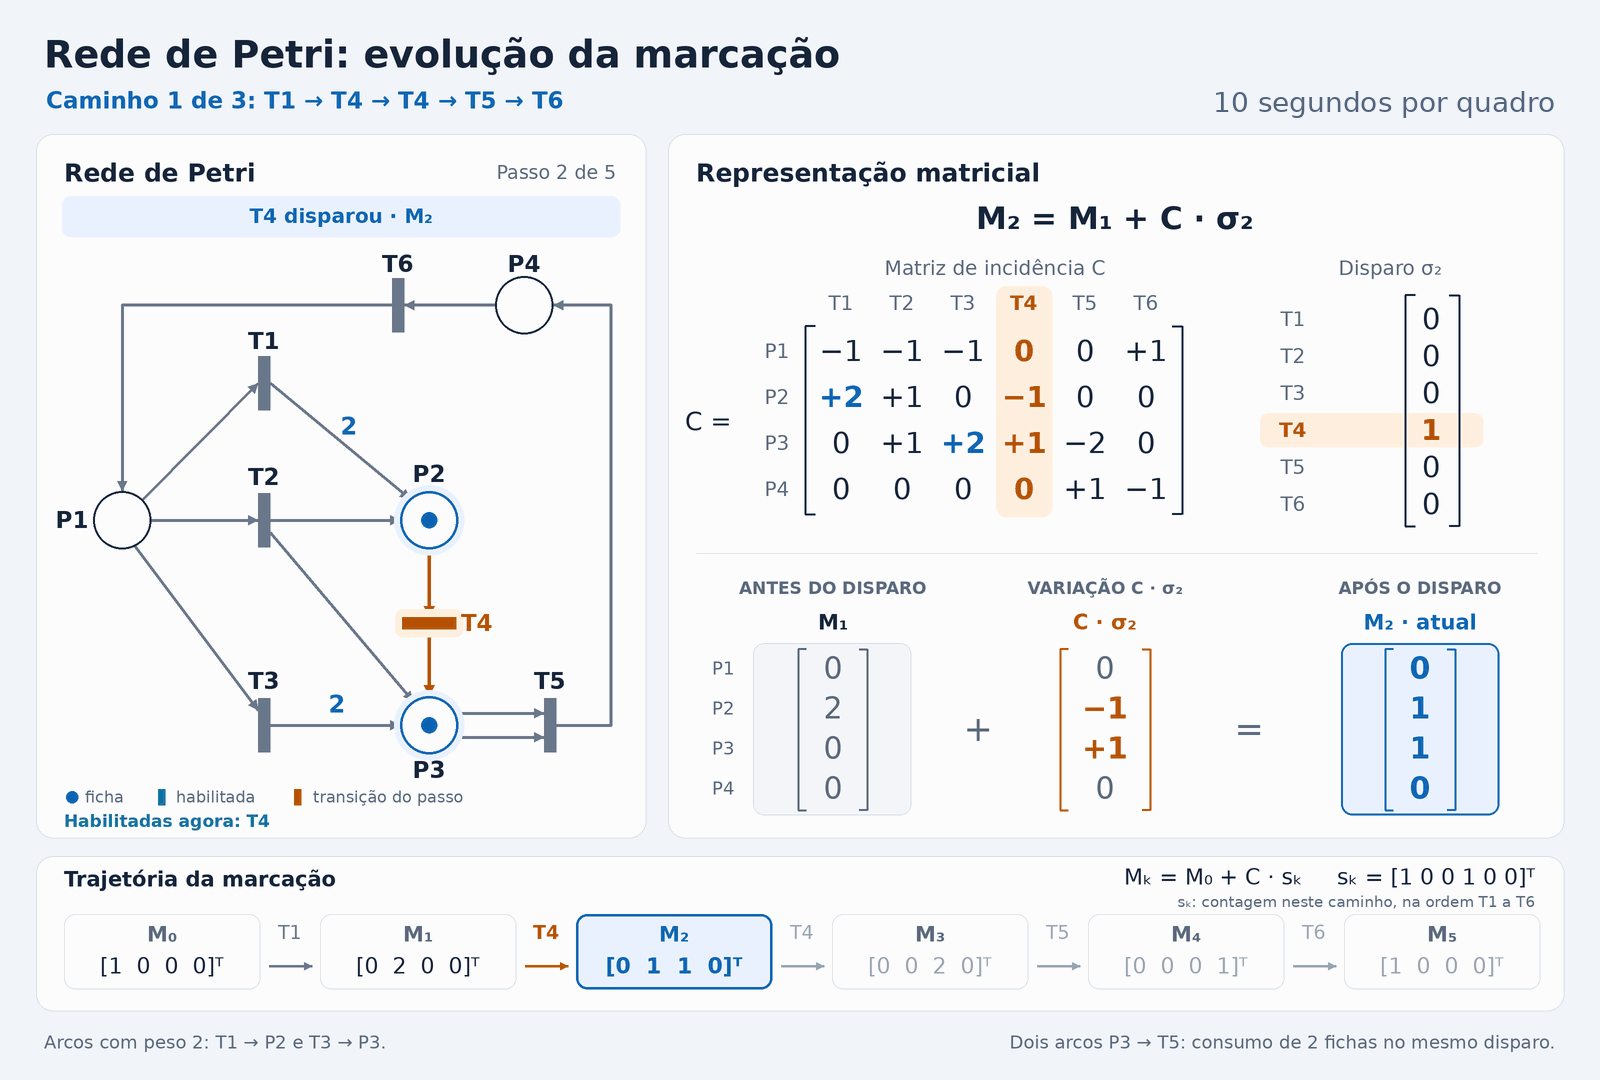

Lugar,Antes,Variação,Depois
P1,0,0,0
P2,2,-1,1
P3,0,1,1
P4,0,0,0


In [29]:
def mostrar_passo(caminho, passo):
    if caminho not in CAMINHOS:
        raise ValueError("Escolha o caminho T1, T2 ou T3.")
    seq = CAMINHOS[caminho]
    if not isinstance(passo, int) or not 1 <= passo <= len(seq):
        raise ValueError(f"O passo deve estar entre 1 e {len(seq)}.")
    estados = simular(seq)
    antes, depois, t = estados[passo-1], estados[passo], seq[passo-1]
    sigma = vetor_disparo(t)
    display(HTML(f"<h4>Caminho {caminho} · passo {passo}/{len(seq)} · disparo de {t}</h4>"))
    display(Math(latex_matriz(antes) + "+" + latex_matriz(C) + latex_matriz(sigma)
                 + "=" + latex_matriz(depois)))
    # Cada disparo tem um quadro de preparação e um de resultado.
    indice_quadro = INICIO_CAMINHO[caminho] + 2 * passo
    mostrar_quadro_gif(indice_quadro)
    tabela("Conferência componente a componente", ["Lugar", "Antes", "Variação", "Depois"],
           [[p, int(antes[i,0]), int((C @ sigma)[i,0]), int(depois[i,0])] for i,p in enumerate(LUGARES)])


CAMINHO = "T1"  # Altere aqui: "T1", "T2" ou "T3".
PASSO = 2       # Altere aqui e execute novamente para avançar.
mostrar_passo(CAMINHO, PASSO)

## 5. Um disparo e a contagem acumulada são vetores diferentes

$\sigma_k$ informa **qual transição disparou no passo $k$**. Já $s_n$ informa
**quantas vezes cada transição disparou nos primeiros $n$ passos**:

$$s_n=\sum_{k=1}^{n}\sigma_k.$$

Somando as atualizações sucessivas, os termos intermediários se cancelam:

$$\boxed{M_n=M_0+C s_n}.$$

No caminho por T1, ao final dos cinco passos:

$$
s_5=\begin{bmatrix}1\\0\\0\\2\\1\\1\end{bmatrix}.
$$

A componente de T4 vale **2**, porque T4 disparou duas vezes. Esse vetor
não é o vetor de um único disparo. Como $Cs_5=0$, temos $M_5=M_0$.

O produto também pode ser lido como uma soma de colunas:

$$Cs_5=c_1+2c_4+c_5+c_6=0,$$

em que $c_j$ é a coluna de $C$ correspondente a $T_j$.

In [15]:
def contar_disparos(sequencia):
    s = np.zeros((6, 1), dtype=int)
    for t in sequencia:
        s += vetor_disparo(t)
    return s


for nome, sequencia in CAMINHOS.items():
    s = contar_disparos(sequencia)
    M_final = M0 + C @ s
    mostrar_matriz(f"s_{{{nome}}}", s)
    mostrar_matriz(f"C s_{{{nome}}}", C @ s)
    assert np.array_equal(M_final, simular(sequencia)[-1])

# Agora verificamos a equação acumulada em TODOS os prefixos dos três caminhos.
for sequencia in CAMINHOS.values():
    for n, M in enumerate(simular(sequencia)):
        assert np.array_equal(M, M0 + C @ contar_disparos(sequencia[:n]))
print("Equação acumulada conferida em cada passo dos três caminhos.")

Equação acumulada conferida em cada passo dos três caminhos.


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 5.1 Contar disparos não preserva sua ordem

Compare as sequências:

- **T3 → T5 → T6**: execução permitida a partir de $M_0$;
- **T5 → T3 → T6**: execução proibida, pois T5 não pode ser o primeiro disparo.

As duas têm a mesma contagem $s=[0\ 0\ 1\ 0\ 1\ 1]^T$ e produzem a mesma
expressão $M_0+Cs=M_0$. Portanto, o produto acumulado não certifica que uma
**ordem de disparos proposta** é executável. A habilitação precisa ser
verificada em cada marcação intermediária.

Uma equação algébrica para o estado final e uma sequência efetivamente
executável são verificações relacionadas, mas distintas.

In [16]:
ordem_valida = ["T3", "T5", "T6"]
ordem_invalida = ["T5", "T3", "T6"]
s_valido = contar_disparos(ordem_valida)
s_invalido = contar_disparos(ordem_invalida)
print("As contagens são iguais?", np.array_equal(s_valido, s_invalido))
print("Marcação final da sequência válida:", simular(ordem_valida)[-1].ravel())
try:
    simular(ordem_invalida)
except ValueError as erro:
    print("A segunda ordem foi recusada:", erro)

As contagens são iguais? True
Marcação final da sequência válida: [1 0 0 0]
A segunda ordem foi recusada: T5 não está habilitada em [1, 0, 0, 0].


## 6. Modelos no GitHub: PIPE2 e HPSim

Os modelos estão disponíveis no repositório
[UniRobotica/Petri-nets](https://github.com/UniRobotica/Petri-nets).
Baixe os arquivos enquanto houver conexão e abra-os depois nos respectivos
simuladores para trabalhar offline.

| Simulador | Arquivo | Link direto |
|---|---|---|
| PIPE2 | `MarcacaoDisparoIncidencia.xml` | [Baixar modelo PIPE2](https://raw.githubusercontent.com/UniRobotica/Petri-nets/refs/heads/main/Exemplos/Exemplos_Pipe2/MarcacaoDisparoIncidencia.xml) |
| HPSim | `MatrizIncidencia.hps` | [Baixar modelo HPSim](https://github.com/UniRobotica/Petri-nets/raw/refs/heads/main/Exemplos/Exemplos_HPSim/MatrizIncidencia.hps) |

Os dois arquivos originais podem ser baixados diretamente pelos links
acima e salvos no computador para uso offline, preservando seus nomes e parâmetros.
O arquivo HPSim é binário e deve ser aberto no próprio simulador.
No PIPE2, o XML permite conferir os dados diretamente.

**Preparação da atividade offline:** abra o arquivo no aplicativo correspondente,
identifique os lugares e as transições pelo fluxo, reinicie a marcação e
reproduza um caminho por vez. Compare as fichas com os resultados deste
notebook. Verifique os pesos T1 → P2 = 2, T3 → P3 = 2 e consumo total de
P3 por T5 = 2, usando a correspondência de nomes do modelo.

## 7. Animação completa: rede e marcação sincronizadas

A animação abaixo reúne os mesmos três caminhos e usa a mesma matriz $C$.
Os trechos apresentados durante a explicação foram retirados deste GIF.
Na configuração entregue, cada quadro permanece por **10 segundos**:
são **27 quadros**, com duração total de **4min30s** e repetição automática.

O arquivo é `img/rede_petri_corrigida.gif`. Ele é carregado por um caminho
relativo, assim como as figuras e os trechos anteriores. Ao enviar o notebook
para o site, envie também a pasta `img` ao lado dele.

Para uma explicação sem avanço automático, use o visualizador da seção 4.1.

![Rede com evolução da marcação e multiplicação matricial nos três caminhos.](img/rede_petri_corrigida.gif)

**Onde mudar o tempo por quadro:** abra **Show code** na célula seguinte e
altere `DURACAO_QUADRO_MS = 10000`. O valor está em milissegundos:
`10000` = 10 segundos; `5000` = 5 segundos; `2000` = 2 segundos.
Quanto menor o tempo, mais rápida a animação.

Execute essa célula para salvar o GIF completo e todos os trechos com o novo
tempo na pasta `img`. A legenda de tempo dentro dos quadros também será
atualizada. Depois, reabra o notebook ou atualize a página para recarregar
os arquivos; no site, publique novamente os GIFs atualizados.


In [17]:
# TEMPO DE EXIBIÇÃO DE CADA QUADRO — altere este valor e execute a célula.
DURACAO_QUADRO_MS = 10000

from PIL import ImageDraw, ImageFont
from matplotlib import font_manager

TRECHOS_GIF = {
    "t1_primeiro_disparo.gif": (0, 3),
    "t4_dois_disparos.gif": (2, 7),
    "t5_t6_fechamento.gif": (6, 11),
    "caminho_t1.gif": (0, 11),
    "caminho_t2.gif": (11, 20),
    "caminho_t3.gif": (20, 27),
}


def salvar_gifs(duracao_ms, pasta_img=Path("img")):
    """Atualiza o tempo e a legenda do GIF completo e de todos os trechos."""
    if (not isinstance(duracao_ms, int) or isinstance(duracao_ms, bool)
            or not 20 <= duracao_ms <= 655350 or duracao_ms % 10):
        raise ValueError("Use um inteiro de 20 a 655350 ms, múltiplo de 10.")
    pasta_img = Path(pasta_img)
    completo = pasta_img / "rede_petri_corrigida.gif"
    quadros = []
    with PILImage.open(completo) as animacao:
        if animacao.n_frames != 27 or animacao.size != (1600, 1080):
            raise ValueError("Esta célula usa o GIF original de 27 quadros, 1600 × 1080.")
        for i in range(animacao.n_frames):
            animacao.seek(i)
            quadros.append(animacao.convert("RGB").copy())

    segundos = f"{duracao_ms / 1000:g}".replace(".", ",")
    unidade = "segundo" if duracao_ms == 1000 else "segundos"
    fonte = ImageFont.truetype(font_manager.findfont("DejaVu Sans"), 28)
    for quadro in quadros:
        desenho = ImageDraw.Draw(quadro)
        desenho.rectangle((1170, 78, 1568, 122), fill=quadro.getpixel((1590, 85)))
        desenho.text((1555, 86), f"{segundos} {unidade} por quadro",
                     font=fonte, fill="#52647D", anchor="ra")

    arquivos = {"rede_petri_corrigida.gif": (0, len(quadros)), **TRECHOS_GIF}
    for nome, (inicio, fim) in arquivos.items():
        quadros[inicio].save(
            pasta_img / nome, save_all=True,
            append_images=quadros[inicio + 1:fim], duration=duracao_ms,
            loop=0, disposal=2, optimize=False,
        )
    quadros[0].save(pasta_img / "PN_algebraLinear.png")
    total_s = len(quadros) * duracao_ms / 1000
    print(f"GIF completo e {len(TRECHOS_GIF)} trechos salvos em {pasta_img}/.")
    print(f"Tempo por quadro: {duracao_ms} ms. Duração total: {total_s:g} segundos.")


salvar_gifs(DURACAO_QUADRO_MS)


GIF completo e 6 trechos salvos em img/.
Tempo por quadro: 10000 ms. Duração total: 270 segundos.


## 8. Referências e arquivos de apoio

- **UniRobótica.** [Repositório Petri-nets](https://github.com/UniRobotica/Petri-nets).
  Modelos disponibilizados pelo docente para uso no PIPE2 e no HPSim.
- **UniRobótica.** [MarcacaoDisparoIncidencia.xml — modelo PIPE2](https://raw.githubusercontent.com/UniRobotica/Petri-nets/refs/heads/main/Exemplos/Exemplos_Pipe2/MarcacaoDisparoIncidencia.xml).
- **UniRobótica.** [MatrizIncidencia.hps — modelo HPSim](https://github.com/UniRobotica/Petri-nets/raw/refs/heads/main/Exemplos/Exemplos_HPSim/MatrizIncidencia.hps).
- **NumPy Developers.** [numpy.matmul](https://numpy.org/doc/stable/reference/generated/numpy.matmul.html).
  Referência oficial do produto matricial e do operador `@`.
- **Project Jupyter.** [Installing Jupyter](https://jupyter.org/install).
  Orientações oficiais para preparar o ambiente local.

Os dois modelos foram obtidos em **6 de novembro de 2026**. O XML PIPE2 foi
comparado com as matrizes desta aula, após a correspondência dos identificadores.
O HPSim permanece no formato binário original do aplicativo.

**Pergunta de fechamento:** em um disparo habilitado, qual coluna de $C$ é
selecionada, o que significam os sinais dessa coluna e como ela modifica $M$?

## APÊNDICE A: Por que esse formalismo permite simular a evolução da rede?

O formalismo matricial representa **o estado da rede e as regras para modificá-lo**. A marcação $M$ informa quantas fichas existem em cada lugar; $Pre$ estabelece as condições de habilitação; e $C$ descreve a variação causada por cada disparo.

Usando as matrizes já definidas no notebook, podemos simular o caminho **T3 → T5 → T6**, conforme o código seguinte, **cada marcação calculada se torna a entrada do próximo passo.** Ao repetir a verificação de habilitação e a atualização matricial, o programa reproduz a evolução das fichas. Neste caminho, a rede retorna à marcação inicial; outras escolhas de transições permitem simular outros caminhos.



In [30]:
M = M0.copy()

for transicao in ["T3", "T5", "T6"]:
    j = TRANSICOES.index(transicao)

    # 1. Verificar se existem fichas suficientes.
    if not np.all(M >= Pre[:, j:j+1]):
        raise ValueError(f"{transicao} não está habilitada.")

    # 2. Selecionar a transição no vetor de disparo.
    sigma = np.zeros((C.shape[1], 1), dtype=int)
    sigma[j, 0] = 1

    # 3. Calcular a marcação usada no próximo passo.
    M = M + C @ sigma

    print(f"Após {transicao}: {M.ravel().tolist()}")


Após T3: [0, 0, 2, 0]
Após T5: [0, 0, 0, 1]
Após T6: [1, 0, 0, 0]
